### Single Neuron testing with Leaky (model 1, layered)
snntorch: Version: 0.7.0

- this file can be used in the limitation/discussion section of my thesis since I look at the neuron behaviour, if I extend it to mean and sd of spikes/membrane trace and compare it against hxtorch it could be an explaination why accuracy is different

#### Simulation: Leaky vs LIF

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import snntorch.surrogate as surrogate
from aiexperiments.asynctorch.nn.neuron.lif_state import LIFState


from aiexperiments.networks.components.matrix.leaky import Leaky
from aiexperiments.networks.base_network import calc_exp_decay_factor

# 2. neuron settings (SHD, from the paper's Table 6 and the model sheet)
dt_us, tau_us = 10000, 100000
beta = calc_exp_decay_factor(dt_us, tau_us)   
thr = 0.3                                     


T = 100
w = 0.1                                       
x = np.zeros(T)
x[::2] = 1.0                                 

In [ ]:
neuron = Leaky(beta=beta, init_hidden=True, output=True,
               spike_grad=surrogate.atan(alpha=10.0),
               threshold=thr, reset_mechanism="zero")
neuron.reset_hidden()                        


mem, spk = [], []
with torch.no_grad():
    for t in range(T):
        current = torch.tensor([[w * x[t]]], dtype=torch.float32)  
        s, m = neuron(current)
        mem.append(m.item())
        spk.append(s.item())


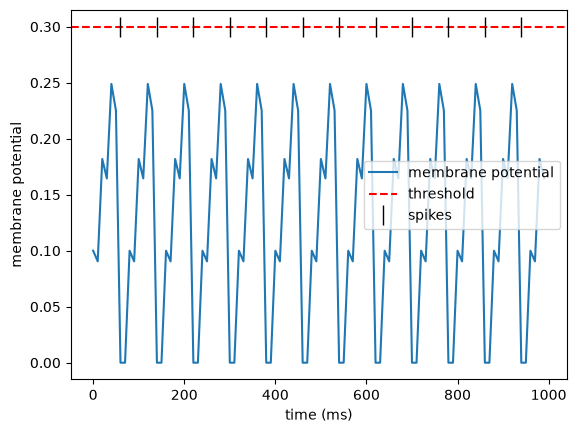

In [ ]:
# save everything for hxtorch later
# np.savez("single_neuron_reference.npz", x=x, w=w, beta=beta, thr=thr,
#          dt_us=dt_us, mem=np.array(mem), spk=np.array(spk))

# plot
t_ms = np.arange(T) * dt_us / 1000
spk = np.array(spk)
plt.plot(t_ms, mem, label="membrane potential")
plt.axhline(thr, color="r", ls="--", label="threshold")
plt.plot(t_ms[spk > 0], np.full(int((spk > 0).sum()), thr), "k|",
         markersize=15, label="spikes")
plt.xlabel("time (ms)")
plt.ylabel("membrane potential")
plt.legend()
plt.show()

- one input spike every second step
- the plot doesnt show the membrane potential reaching the threshold as the "mem" returns the membrane potential after the reset (therefore 0)
- spike ticks sit at abt 60, 140 and 220, where the calculation crosses 0.3 (but then membrane potential is set to 0)

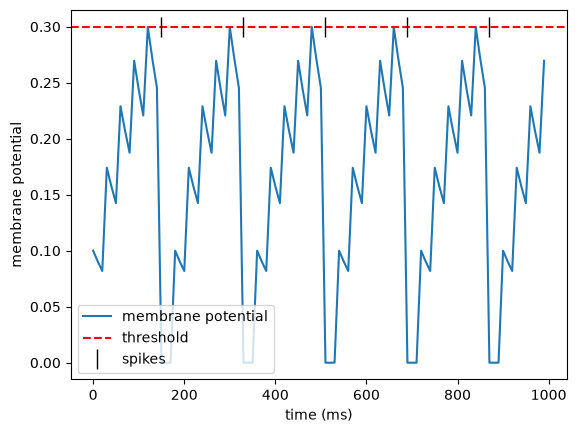

In [ ]:
# plot
t_ms = np.arange(T) * dt_us / 1000
spk = np.array(spk)
plt.plot(t_ms, mem, label="membrane potential")
plt.axhline(thr, color="r", ls="--", label="threshold")
plt.plot(t_ms[spk > 0], np.full(int((spk > 0).sum()), thr), "k|",
         markersize=15, label="spikes")
plt.xlabel("time (ms)")
plt.ylabel("membrane potential")
plt.legend()
plt.show()

- the membrane trace seems to be very close to the threshold (but doesnt meet/cross it) which is why the plot looks different from the other leaky neuron implementation (with an incoming spike at every second step, here it is every third)

##### Single neuron testing with LIF (model 2-24, unlayered)

- neuron_state = LIFState( <br>
            neurons_per_layer, <br>
            builder_params.tau_m, <br>
            membrane_threshold, <br>
            sync_threshold, (0 unles sync_threshold extension is set)<br>
            spike_grad, <br>
            sync_grad, <br>
            builder_params.device, <br>
            refrac_dropout=refrac_dropout, <br>
            apply_refrac=apply_refrac, <br>
        )

- spike at every second timestep

In [9]:
device = torch.device("cpu")
dt_us, tau_us, thr = 10000, 100000, 0.3
sg = surrogate.atan(alpha=10.0)

neuron_state = LIFState([1], tau_us, thr, 0.0, sg, sg, device,
                        refrac_dropout=0.0, apply_refrac=True)
neuron_state._init_state(batch_size=1)    # forward() raises an error without this

# same T, w, x
mem2, spk2 = [], []
with torch.no_grad():
    for t in range(T):
        neuron_state.step_dynamics(dt_us)                          # decay exp(-dt/tau)
        I = torch.tensor([[w * x[t]]], dtype=torch.float32)        # summed current
        n = torch.tensor([[x[t]]], dtype=torch.float32)            # number of incoming spikes
        s = neuron_state.forward(I, n)
        spk2.append(s.item())
        mem2.append(neuron_state.get_post_spike_state().item())    # membrane after reset

In [10]:
print(np.allclose(mem, mem2, atol=1e-6), np.array_equal(spk, spk2))

False False


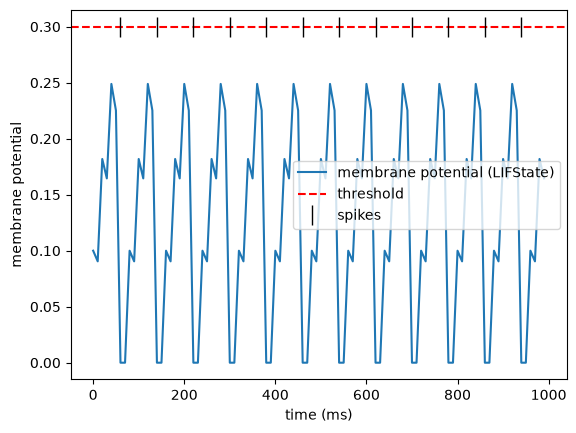

In [11]:
# 7. plot (LIFState run)
t_ms = np.arange(T) * dt_us / 1000
spk2 = np.array(spk2)
plt.plot(t_ms, mem2, label="membrane potential (LIFState)")
plt.axhline(thr, color="r", ls="--", label="threshold")
plt.plot(t_ms[spk2 > 0], np.full(int((spk2 > 0).sum()), thr), "k|",
         markersize=15, label="spikes")
plt.xlabel("time (ms)")
plt.ylabel("membrane potential")
plt.legend()
plt.show()

- without the numerical results (which may fluctuate slightly due to noise) the behaviour of leaky vs LIF seems to be the same
- this is not evidence enough to assign meaning to it (eg responsible for for accuracy drop), since it is very small scale and only concerns one neuron
- to make it significant, have multiple runs, plot mean and sd

In [13]:
# one input spike every third step
device = torch.device("cpu")
dt_us, tau_us, thr = 10000, 100000, 0.3
sg = surrogate.atan(alpha=10.0)
x = np.zeros(T)
x[::3] = 1.0  

neuron_state = LIFState([1], tau_us, thr, 0.0, sg, sg, device,
                        refrac_dropout=0.0, apply_refrac=True)
neuron_state._init_state(batch_size=1)

mem3, spk3 = [], []
with torch.no_grad():
    for t in range(T):
        neuron_state.step_dynamics(dt_us)                          # decay exp(-dt/tau)
        I = torch.tensor([[w * x[t]]], dtype=torch.float32)        # summed current
        n = torch.tensor([[x[t]]], dtype=torch.float32)            # number of incoming spikes
        s = neuron_state.forward(I, n)
        spk3.append(s.item())
        mem3.append(neuron_state.get_post_spike_state().item()) 

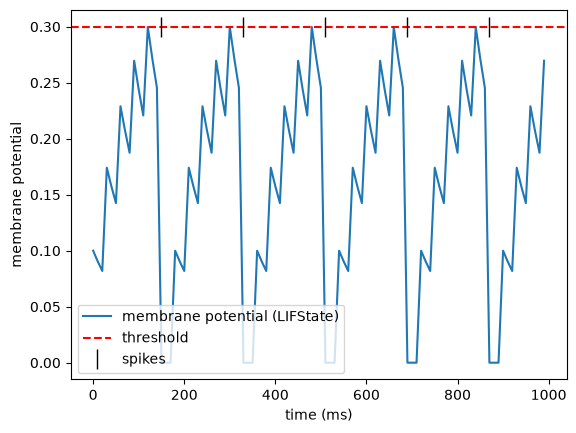

In [ ]:
# plot (LIFState run)
t_ms = np.arange(T) * dt_us / 1000
spk3 = np.array(spk3)
plt.plot(t_ms, mem3, label="membrane potential (LIFState)")
plt.axhline(thr, color="r", ls="--", label="threshold")
plt.plot(t_ms[spk3 > 0], np.full(int((spk3 > 0).sum()), thr), "k|",
         markersize=15, label="spikes")
plt.xlabel("time (ms)")
plt.ylabel("membrane potential")
plt.legend()
plt.show()

#### Simulation vs BSS2
- in the eBrains drive I want to inspect how the neuron behaves when all parameters are set, I use LIF for simulation and the hxtorch equivalent of LIF 
- threshold is changed since BSS2 only allows for integer values
- the results are not meaningful for my thesis (not enough to assign meaning to it) but helpful for understanding

In [1]:
import torch, tonic.transforms as T
from aiexperiments.datasets.shd_pooled import SHD
from aiexperiments.datasets.transforms import ToFrame, TimeSliceTransform

tf = T.Compose([ToFrame(sensor_size=SHD.sensor_size, timestep_size=10000),
                torch.from_numpy, TimeSliceTransform(100)])
ds = SHD(save_to="./data", transform=tf, train=True)
for i in [0, 1, 500, 8000]:
    a, ya = ds[i]; b, yb = ds[i]
    print(i, tuple(a.shape), a.dtype, torch.equal(a, b), ya == yb)

c:\Users\shago\anaconda3\envs\asyncinf-np1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0 (100, 2, 128) torch.int16 True True
1 (100, 2, 128) torch.int16 True True
500 (100, 2, 128) torch.int16 True True
8000 (100, 2, 128) torch.int16 True True


#### Inspect the weights from model 25/26

In [2]:
import torch

for mid in [25, 26]:
    sd = torch.load(f"models/shd/{mid}.pt", map_location="cpu", weights_only=True)
    print(f"\n=== Model {mid} ===")
    for key, value in sd.items():
        if key.endswith("weight") and value.numel() > 0:
            w = value.float()
            print(f"{key:18s} shape {tuple(w.shape)}  "
                  f"min {w.min():.3f}  max {w.max():.3f}  "
                  f"mean |w| {w.abs().mean():.3f}")
        elif value.numel() == 1:
            print(f"{key:18s} = {value.item():.6g}")          # e.g. threshold, beta
        else:
            print(f"{key:18s} shape {tuple(value.shape)}")    # e.g. sync_thresholds


=== Model 25 ===
layers.0.weight    shape (64, 256)  min -1.067  max 0.729  mean |w| 0.102
layers.1.threshold = 0.3
layers.1.graded_spikes_factor = 1
layers.1.reset_mechanism_val = 1
layers.1.beta      = 0.904837
layers.3.weight    shape (64, 64)  min -4.164  max 1.006  mean |w| 0.248
layers.4.threshold = 0.3
layers.4.graded_spikes_factor = 1
layers.4.reset_mechanism_val = 1
layers.4.beta      = 0.904837
layers.6.weight    shape (64, 64)  min -2.086  max 0.852  mean |w| 0.198
layers.7.threshold = 0.3
layers.7.graded_spikes_factor = 1
layers.7.reset_mechanism_val = 1
layers.7.beta      = 0.904837
layers.9.weight    shape (20, 64)  min -1.802  max 0.919  mean |w| 0.254
layers.10.threshold = 0.3
layers.10.graded_spikes_factor = 1
layers.10.reset_mechanism_val = 1
layers.10.beta     = 0.904837

=== Model 26 ===
layers.0.weight    shape (64, 256)  min -0.733  max 0.461  mean |w| 0.056
layers.3.weight    shape (64, 64)  min -1.737  max 0.811  mean |w| 0.160
layers.6.weight    shape (64, 64)

In [3]:

sd = torch.load("models/shd/26.pt", map_location="cpu", weights_only=True)
print("\n=== Model 26 ===")
for key, value in sd.items():
    if key.endswith("weight") and value.numel() > 0:
        w = value.float()
        print(f"{key:18s} shape {tuple(w.shape)}  "
                f"min {w.min():.3f}  max {w.max():.3f}  "
                f"mean |w| {w.abs().mean():.3f}")
    elif value.numel() == 1:
        print(f"{key:18s} = {value.item():.6g}")          # e.g. threshold, beta
    else:
        print(f"{key:18s} shape {tuple(value.shape)}")    # e.g. sync_thresholds


=== Model 26 ===
layers.0.weight    shape (64, 256)  min -0.733  max 0.461  mean |w| 0.056
layers.3.weight    shape (64, 64)  min -1.737  max 0.811  mean |w| 0.160
layers.6.weight    shape (64, 64)  min -2.591  max 0.764  mean |w| 0.185
layers.9.weight    shape (20, 64)  min -2.446  max 1.045  mean |w| 0.464
layers.12.weight   shape (0, 20)
sync_thresholds    shape (212,)


- Model 25, layered (SNNTorchFcMLP): saves the weights plus the neuron settings of each layer (threshold, β, reset). That’s PyTorch’s normal behaviour for snnTorch’s Leaky neurons.
- Model 26, RS (AsyncTorchFcMLP): its own save function stores only the weights and sync_thresholds. We saw this in fc_mlp.py in an earlier chat (its state_dict method). The neuron settings aren’t saved because they don’t come from the file anyway.

#### Save data and model weights as .npz

In [3]:
import torch, numpy as np, tonic.transforms as T
from aiexperiments.datasets.shd_pooled import SHD
from aiexperiments.datasets.transforms import ToFrame, TimeSliceTransform

# the same data pipeline as roels training and testing
tf = T.Compose([ToFrame(sensor_size=SHD.sensor_size, timestep_size=10000),
                torch.from_numpy, TimeSliceTransform(100)])
ds = SHD(save_to="./data", transform=tf, train=False)     # train=False: the test set

# frames have shape (100, 2, 128); [:, 1, :] keeps polarity 1, the one with the spikes
X = np.stack([ds[i][0][:, 1, :].numpy() for i in range(len(ds))])   # (2264, 100, 128)
y = np.array([int(ds[i][1]) for i in range(len(ds))])               # labels 0-19

print(X.shape, X.dtype, "max count per bin:", X.max())
np.savez_compressed("z_alam_thesis_files/shd_test_128.npz", X=X, y=y)

(2264, 100, 128) int16 max count per bin: 27


In [ ]:
import torch
import numpy as np


model_id = 26                                  # change to 26 for the RS model
pt_path = f"models/shd/{model_id}.pt"          # where Roel's code saved the trained model
npz_path = f"z_alam_thesis_files/model{model_id}_weights.npz"      # the file we will create


state_dict = torch.load(pt_path, map_location="cpu", weights_only=True)

print("Entries in the file:")
for name in state_dict.keys():
    print("  ", name)


w_input_to_hidden1   = state_dict["layers.0.weight"]
w_hidden1_to_hidden2 = state_dict["layers.3.weight"]
w_hidden2_to_hidden3 = state_dict["layers.6.weight"]
w_hidden3_to_output  = state_dict["layers.9.weight"]

w0 = w_input_to_hidden1.detach().clone().float().numpy()
w1 = w_hidden1_to_hidden2.detach().clone().float().numpy()
w2 = w_hidden2_to_hidden3.detach().clone().float().numpy()
w3 = w_hidden3_to_output.detach().clone().float().numpy()

print("Shapes before removing the empty polarity:")
print("  w0:", w0.shape, " w1:", w1.shape, " w2:", w2.shape, " w3:", w3.shape)
# expected: w0 (64, 256), w1 (64, 64), w2 (64, 64), w3 (20, 64)


empty_part = w0[:, 0:128]
real_part  = w0[:, 128:256]

largest_empty_weight = np.abs(empty_part).max()
print("Largest absolute weight in the empty polarity:", largest_empty_weight)


w0 = real_part                                  # keep only the 128 real channels
print("New shape of w0:", w0.shape)

# np.savez stores several arrays in one file; each gets a name (w0, w1, ...)
np.savez(npz_path, w0=w0, w1=w1, w2=w2, w3=w3)
print("Saved:", npz_path)


check = np.load(npz_path)
print("Arrays in the saved file:", list(check.keys()))
for name in ["w0", "w1", "w2", "w3"]:
    print("  ", name, check[name].shape)
# expected: w0 (64, 128), w1 (64, 64), w2

Entries in the file:
   layers.0.weight
   layers.3.weight
   layers.6.weight
   layers.9.weight
   layers.12.weight
   sync_thresholds
Shapes before removing the empty polarity:
  w0: (64, 256)  w1: (64, 64)  w2: (64, 64)  w3: (20, 64)
Largest absolute weight in the empty polarity: 2.61603e-40
New shape of w0: (64, 128)
Saved: z_alam_thesis_files/model26_weights.npz
Arrays in the saved file: ['w0', 'w1', 'w2', 'w3']
   w0 (64, 128)
   w1 (64, 64)
   w2 (64, 64)
   w3 (20, 64)
